# 03 — Tạo đặc trưng từ nhiều bảng

Notebook độc lập, không gọi src/. Đọc tám bảng đã làm sạch trong data/processed/; giữ nguyên nguồn và split.

1. Kiểm tra nguồn và split.
2. Quy tắc tổng hợp và mốc lịch sử.
3. Bureau balance → bureau → khách hàng.
4. Previous application → khách hàng.
5. POS/thẻ tín dụng: snapshot → khoản vay → khách hàng.
6. Installments: lần thanh toán → kỳ trả → khoản vay → khách hàng.
7. Application: tỷ lệ nghiệp vụ, ghép và xuất dữ liệu.

Output: data/processed/features/. CSV báo cáo: reports/tables/. Không scaling, encoder học từ dữ liệu, imputation theo thống kê, feature selection hoặc train. Không dùng TARGET để tạo đặc trưng.

## 1. Kiểm tra nguồn và split
Kiểm tra SHA-256 theo manifest notebook 02. Giữ nguyên train/val và 5 fold. application_train_features.parquet chứa toàn bộ tập có nhãn, gồm development và holdout; fold không phải predictor.

In [1]:
import hashlib
import json
import os
from datetime import datetime, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

def locate_project_root(cwd: Path) -> Path:
    override = os.getenv("HOME_CREDIT_ROOT")
    if override:
        root = Path(override).expanduser().resolve()
        if not (root / "data" / "raw").is_dir():
            raise FileNotFoundError(f"HOME_CREDIT_ROOT không chứa data/raw/: {root}")
        return root
    for folder in (cwd.resolve(), *cwd.resolve().parents):
        if (folder / "data" / "raw").is_dir():
            return folder
    raise FileNotFoundError("Không tìm thấy data/raw/. Đặt HOME_CREDIT_ROOT.")

def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

def labeled_source_sha256(df: pd.DataFrame) -> str:
    array = df.sort_values(ID_COL)[[ID_COL, TARGET_COL]].to_numpy(dtype="int64")
    return hashlib.sha256(np.ascontiguousarray(array).tobytes()).hexdigest()

ROOT = locate_project_root(Path.cwd())
SOURCE_DIR = ROOT / "data" / "processed"
OUTPUT_DIR = SOURCE_DIR / "features"
SPLIT_DIR = ROOT / "data" / "splits"
REPORT_DIR = ROOT / "reports" / "tables"
ID_COL, TARGET_COL = "SK_ID_CURR", "TARGET"
TABLES = ["application_train", "application_test", "bureau", "bureau_balance", "previous_application",
          "POS_CASH_balance", "credit_card_balance", "installments_payments"]
EXPORT_REPORTS = True
CUSTOMER_PARTITION_WIDTH = 50_000
BUREAU_PARTITION_WIDTH = 250_000
FEATURE_VERSION = "features_v1"
REBUILD_OUTPUTS = False  # True: chủ động ghi lại artifact dẫn xuất; không ghi nguồn/split.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 14)
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110})


def save_report(frame: pd.DataFrame, name: str) -> None:
    if EXPORT_REPORTS:
        REPORT_DIR.mkdir(parents=True, exist_ok=True)
        frame.to_csv(REPORT_DIR / name, index=False, encoding="utf-8-sig")


cleaning_manifest = json.loads((SOURCE_DIR / "cleaning_manifest.json").read_text(encoding="utf-8"))
assert set(cleaning_manifest["tables"]) == set(TABLES)
source_hashes = {}
for table in TABLES:
    source_hashes[table] = file_sha256(SOURCE_DIR / f"{table}.parquet")
    assert source_hashes[table] == cleaning_manifest["tables"][table]["output_sha256"], table
split_hashes = {name: file_sha256(SPLIT_DIR / name) for name in ["train.parquet", "val.parquet", "train_val_metadata.json"]}
labels = pd.read_parquet(SOURCE_DIR / "application_train.parquet", columns=[ID_COL, TARGET_COL])
test_ids = pd.read_parquet(SOURCE_DIR / "application_test.parquet", columns=[ID_COL])
train_split = pd.read_parquet(SPLIT_DIR / "train.parquet")
val_split = pd.read_parquet(SPLIT_DIR / "val.parquet")
split_metadata = json.loads((SPLIT_DIR / "train_val_metadata.json").read_text(encoding="utf-8"))
assert labeled_source_sha256(labels) == split_metadata["source_sha256"]
assert labels.notna().all().all() and labels[ID_COL].is_unique and set(labels[TARGET_COL]) == {0, 1}
assert list(train_split.columns) == [ID_COL, "fold"] and list(val_split.columns) == [ID_COL]
assert train_split.notna().all().all() and val_split.notna().all().all()
assert train_split[ID_COL].is_unique and val_split[ID_COL].is_unique
assert not set(train_split[ID_COL]) & set(val_split[ID_COL])
assert set(train_split[ID_COL]) | set(val_split[ID_COL]) == set(labels[ID_COL])
assert set(train_split.fold) == set(range(5))
assert abs(len(val_split) / len(labels) - 0.2) <= 1 / len(labels)
application_ids = pd.concat([labels[[ID_COL]], test_ids], ignore_index=True)
assert application_ids[ID_COL].notna().all() and application_ids[ID_COL].is_unique
print(f"Nguồn: 8 bảng; train={len(train_split):,}, val={len(val_split):,}; split giữ nguyên.")

Nguồn: 8 bảng; train=246,008, val=61,503; split giữ nguyên.


## 2. Quy tắc tổng hợp và lịch sử

- Mẫu số thiếu hoặc không dương → missing. Tổng nhóm toàn missing → missing (min_count=1).
- size đếm bản ghi, count đếm giá trị không thiếu. MEAN_LOAN là trung bình theo khoản, không giả làm trung bình toàn snapshot.
- Chỉ dùng DAYS_CREDIT <= 0 và cập nhật bureau không sau ngày 0; DAYS_DECISION <= 0; MONTHS_BALANCE <= 0; kỳ trả có DAYS_INSTALMENT <= 0.
- Thanh toán sau ngày 0 không tính là đã quan sát. Thiếu mốc cần thiết → loại khỏi phép tổng hợp đó và ghi audit.
- Thiếu timestamp đầy đủ nên không bảo đảm point-in-time correctness hoàn toàn.
- Orphan SK_ID_PREV vẫn tổng hợp trực tiếp theo SK_ID_CURR. Dừng nếu khoản vay đã biết gắn sai khách hàng.
- Bureau balance không khớp bureau: giữ bảng theo khoản, báo số dòng không dùng khi ghép.

In [2]:
feature_definitions, audit_rows, artifacts = [], [], {}


def safe_ratio(numerator: pd.Series, denominator: pd.Series) -> pd.Series:
    n = pd.to_numeric(numerator, errors="raise")
    d = pd.to_numeric(denominator, errors="raise")
    return n.div(d.where(d.gt(0))).replace([np.inf, -np.inf], np.nan)


def sum_valid(values: pd.Series) -> float:
    return values.sum(min_count=1)


def aggregate(df: pd.DataFrame, keys: list[str], specs: dict) -> pd.DataFrame:
    named, validity = {}, {}
    for i, (name, (column, op)) in enumerate(specs.items()):
        named[name] = pd.NamedAgg(column=column, aggfunc="sum" if op is sum_valid else op)
        if op is sum_valid:
            temporary = f"__nonmissing_{i}"
            assert temporary not in specs
            named[temporary] = pd.NamedAgg(column=column, aggfunc="count")
            validity[name] = temporary
    result = df.groupby(keys, sort=True, dropna=False).agg(**named).reset_index()
    # Dùng sum/count vectorized để giữ all-missing thành NaN trên hàng triệu nhóm.
    for name, temporary in validity.items():
        result[name] = result[name].where(result.pop(temporary).gt(0))
    assert not result.duplicated(keys).any()
    return result

def define(group: str, name: str, source: str, definition: str) -> None:
    feature_definitions.append({"feature": name, "group": group, "source": source, "definition": definition})


def define_specs(group: str, specs: dict, source: str) -> None:
    for name, (column, op) in specs.items():
        operation = op.__name__ if callable(op) else op
        define(group, name, source, f"{operation}({column}); group by SK_ID_CURR")


def validate_group(frame: pd.DataFrame, key: str = ID_COL, allow_target: bool = False) -> None:
    assert frame[key].notna().all() and frame[key].is_unique and frame.columns.is_unique
    if not allow_target:
        assert TARGET_COL not in frame
    for col in frame.select_dtypes(include="number"):
        assert not np.isinf(frame[col].to_numpy(dtype=float)).any(), col
    if key == ID_COL:
        assert frame[key].isin(application_ids[ID_COL]).all()


def persist(frame: pd.DataFrame, name: str, key: str = ID_COL, allow_target: bool = False) -> None:
    validate_group(frame, key, allow_target)
    path = OUTPUT_DIR / name
    if not path.exists() or REBUILD_OUTPUTS:
        temporary = path.with_suffix(".parquet.inprogress")
        if temporary.exists():
            raise FileExistsError(temporary)
        frame.to_parquet(temporary, engine="pyarrow", compression="snappy", index=False)
        temporary.replace(path)
    offset = 0
    with pq.ParquetFile(path) as reader:
        assert reader.schema_arrow.names == list(frame.columns)
        for batch in reader.iter_batches(batch_size=65_536):
            saved = batch.to_pandas()
            pd.testing.assert_frame_equal(saved, frame.iloc[offset:offset+len(saved)].reset_index(drop=True))
            offset += len(saved)
    assert offset == len(frame)
    artifacts[name] = {"sha256": file_sha256(path), "n_rows": len(frame), "n_columns": len(frame.columns)}


def partitions(table: str, column: str, width: int, columns: list[str]):
    path = SOURCE_DIR / f"{table}.parquet"
    pf = pq.ParquetFile(path)
    idx = pf.schema_arrow.names.index(column)
    stats = [pf.metadata.row_group(i).column(idx).statistics for i in range(pf.num_row_groups)]
    if not stats or any(s is None or not s.has_min_max for s in stats):
        raise ValueError(f"Thiếu min/max metadata: {table}.{column}")
    assert all(s.null_count == 0 for s in stats), f"Khóa phân khoảng null: {table}"
    low, high = min(s.min for s in stats), max(s.max for s in stats)
    seen = 0
    for lower in range(int(low) // width * width, int(high) + 1, width):
        part = pd.read_parquet(path, columns=columns,
                               filters=[(column, ">=", lower), (column, "<", lower+width)], use_threads=False)
        seen += len(part)
        if not part.empty:
            yield part
    assert seen == pf.metadata.num_rows, table


previous_owners = pd.read_parquet(SOURCE_DIR / "previous_application.parquet", columns=["SK_ID_PREV", ID_COL])
assert previous_owners.SK_ID_PREV.notna().all() and previous_owners.SK_ID_PREV.is_unique


def check_owners(frame: pd.DataFrame, table: str) -> None:
    assert frame[[ID_COL, "SK_ID_PREV"]].notna().all().all()
    assert frame[ID_COL].isin(application_ids[ID_COL]).all()
    pairs = frame[[ID_COL, "SK_ID_PREV"]].drop_duplicates()
    matched = pairs.merge(previous_owners.rename(columns={ID_COL: "OWNER_CURR"}), on="SK_ID_PREV", how="left", validate="many_to_one")
    assert not (matched.OWNER_CURR.notna() & matched.OWNER_CURR.ne(matched[ID_COL])).any(), table
    audit_rows.append({"stage": table, "metric": "orphan_previous_loan_pairs_retained", "n": int(matched.OWNER_CURR.isna().sum())})


def past_rows(frame: pd.DataFrame, table: str, column: str) -> pd.DataFrame:
    valid = frame[column].notna() & frame[column].le(0)
    audit_rows.extend([
        {"stage": table, "metric": "input_rows", "n": len(frame)},
        {"stage": table, "metric": "future_or_missing_time_rows_excluded", "n": int((~valid).sum())},
        {"stage": table, "metric": "eligible_rows", "n": int(valid.sum())},
    ])
    return frame.loc[valid].copy()

## 3. Bureau balance → bureau → khách hàng
STATUS 0–5 là tháng có mức quá hạn biết được; 1–5 có quá hạn. C và X không mặc định thành 0 DPD. Tổng hợp mỗi khoản trước khi ghép bureau. Giữ cả tỷ lệ theo tổng số tháng biết DPD và trung bình tỷ lệ theo từng khoản.

In [3]:
bureau_ids = pd.read_parquet(SOURCE_DIR / "bureau.parquet", columns=["SK_ID_BUREAU"])
assert bureau_ids.SK_ID_BUREAU.notna().all() and bureau_ids.SK_ID_BUREAU.is_unique
parts = []
for part in partitions("bureau_balance", "SK_ID_BUREAU", BUREAU_PARTITION_WIDTH, ["SK_ID_BUREAU", "MONTHS_BALANCE", "STATUS"]):
    audit_rows.append({"stage": "bureau_balance", "metric": "rows_without_bureau_parent", "n": int((~part.SK_ID_BUREAU.isin(bureau_ids.SK_ID_BUREAU)).sum())})
    part = past_rows(part, "bureau_balance", "MONTHS_BALANCE")
    part["KNOWN_DPD"] = part.STATUS.isin(["0", "1", "2", "3", "4", "5"]).astype("int8")
    part["LATE_DPD"] = part.STATUS.isin(["1", "2", "3", "4", "5"]).astype("int8")
    result = aggregate(part, ["SK_ID_BUREAU"], {
        "BB_N_MONTHS": ("MONTHS_BALANCE", "size"), "BB_KNOWN_DPD_MONTHS": ("KNOWN_DPD", "sum"),
        "BB_LATE_MONTHS": ("LATE_DPD", "sum"), "BB_MONTH_MIN": ("MONTHS_BALANCE", "min"), "BB_MONTH_MAX": ("MONTHS_BALANCE", "max")})
    result["BB_LATE_RATE"] = safe_ratio(result.BB_LATE_MONTHS, result.BB_KNOWN_DPD_MONTHS)
    parts.append(result)
    print(f"[BB] {len(part):,} hàng → {len(result):,} khoản", flush=True)
    del part, result
bb_loans = pd.concat(parts, ignore_index=True).sort_values("SK_ID_BUREAU").reset_index(drop=True)
del parts
persist(bb_loans, "bureau_balance_by_loan.parquet", "SK_ID_BUREAU")

[BB] 2,672,207 hàng → 85,917 khoản
[BB] 1,932,567 hàng → 62,506 khoản
[BB] 2,495,288 hàng → 77,703 khoản
[BB] 4,798,081 hàng → 137,796 khoản
[BB] 5,349,683 hàng → 160,417 khoản
[BB] 4,331,483 hàng → 122,704 khoản
[BB] 4,270,530 hàng → 125,673 khoản
[BB] 1,450,086 hàng → 44,679 khoản


In [4]:
bureau = pd.read_parquet(SOURCE_DIR / "bureau.parquet", columns=[ID_COL, "SK_ID_BUREAU", "CREDIT_ACTIVE", "DAYS_CREDIT",
    "DAYS_CREDIT_UPDATE", "CREDIT_DAY_OVERDUE", "AMT_CREDIT_SUM", "AMT_CREDIT_SUM_DEBT", "AMT_CREDIT_SUM_OVERDUE"])
assert bureau.SK_ID_BUREAU.is_unique and bureau[ID_COL].isin(application_ids[ID_COL]).all()
bureau = past_rows(bureau, "bureau", "DAYS_CREDIT")
valid = bureau.DAYS_CREDIT_UPDATE.notna() & bureau.DAYS_CREDIT_UPDATE.le(0)
audit_rows.append({"stage": "bureau", "metric": "future_or_missing_update_rows_excluded", "n": int((~valid).sum())})
bureau = bureau.loc[valid].merge(bb_loans, on="SK_ID_BUREAU", how="left", validate="one_to_one")
bureau["IS_ACTIVE"] = bureau.CREDIT_ACTIVE.eq("Active").where(bureau.CREDIT_ACTIVE.isin(["Active", "Closed", "Sold", "Bad debt"])).astype(float)
bureau["RECENT_365"] = bureau.DAYS_CREDIT.ge(-365).astype("int8")
bureau["DEBT_CREDIT_RATIO"] = safe_ratio(bureau.AMT_CREDIT_SUM_DEBT, bureau.AMT_CREDIT_SUM)
specs = {
    "BUREAU_N_LOANS": ("SK_ID_BUREAU", "size"), "BUREAU_ACTIVE_RATE": ("IS_ACTIVE", "mean"),
    "BUREAU_CREDIT_SUM": ("AMT_CREDIT_SUM", sum_valid), "BUREAU_DEBT_SUM": ("AMT_CREDIT_SUM_DEBT", sum_valid),
    "BUREAU_DEBT_MAX": ("AMT_CREDIT_SUM_DEBT", "max"), "BUREAU_OVERDUE_MAX": ("AMT_CREDIT_SUM_OVERDUE", "max"),
    "BUREAU_DPD_MAX": ("CREDIT_DAY_OVERDUE", "max"), "BUREAU_DAYS_CREDIT_MAX": ("DAYS_CREDIT", "max"),
    "BUREAU_N_RECENT_365": ("RECENT_365", "sum"), "BUREAU_BB_N_LOANS": ("BB_N_MONTHS", "count"),
    "BUREAU_BB_MONTHS_SUM": ("BB_N_MONTHS", sum_valid), "BUREAU_BB_KNOWN_MONTHS_SUM": ("BB_KNOWN_DPD_MONTHS", sum_valid),
    "BUREAU_BB_LATE_MONTHS_SUM": ("BB_LATE_MONTHS", sum_valid), "BUREAU_BB_LATE_RATE_MEAN_LOAN": ("BB_LATE_RATE", "mean"),
    "BUREAU_DEBT_CREDIT_RATIO_MEAN_LOAN": ("DEBT_CREDIT_RATIO", "mean")}
bureau_features = aggregate(bureau, [ID_COL], specs)
define_specs("bureau", specs, "bureau + bureau_balance_by_loan")
bureau_features["BUREAU_BB_LATE_RATE_WEIGHTED"] = safe_ratio(bureau_features.BUREAU_BB_LATE_MONTHS_SUM, bureau_features.BUREAU_BB_KNOWN_MONTHS_SUM)
define("bureau", "BUREAU_BB_LATE_RATE_WEIGHTED", "bureau_balance", "sum late months / sum known DPD months on matched eligible loans")
persist(bureau_features, "bureau_features.parquet")
del bureau, bb_loans, bureau_ids
print(f"Bureau: {len(bureau_features):,} khách hàng")

Bureau: 305,810 khách hàng


## 4. Previous application → khách hàng
Số đơn, tỷ lệ duyệt/từ chối, quy mô khoản vay, credit/application và số đơn trong 365 ngày. Mẫu số tỷ lệ trạng thái chỉ gồm trạng thái đã biết trong tập cố định; không điền trạng thái thiếu. Không dùng kết quả kết thúc khoản vay sau ngày 0.

In [5]:
previous = pd.read_parquet(SOURCE_DIR / "previous_application.parquet", columns=[ID_COL, "SK_ID_PREV", "DAYS_DECISION", "NAME_CONTRACT_STATUS", "AMT_APPLICATION", "AMT_CREDIT"])
assert previous.SK_ID_PREV.is_unique and previous[ID_COL].isin(application_ids[ID_COL]).all()
previous = past_rows(previous, "previous_application", "DAYS_DECISION")
known = previous.NAME_CONTRACT_STATUS.isin(["Approved", "Canceled", "Refused", "Unused offer"])
previous["APPROVED"] = previous.NAME_CONTRACT_STATUS.eq("Approved").where(known).astype(float)
previous["REFUSED"] = previous.NAME_CONTRACT_STATUS.eq("Refused").where(known).astype(float)
previous["APPROVED_CREDIT"] = previous.AMT_CREDIT.where(previous.NAME_CONTRACT_STATUS.eq("Approved"))
previous["CREDIT_APPLICATION_RATIO"] = safe_ratio(previous.AMT_CREDIT, previous.AMT_APPLICATION)
previous["RECENT_365"] = previous.DAYS_DECISION.ge(-365).astype("int8")
specs = {"PREV_N_APPLICATIONS": ("SK_ID_PREV", "size"), "PREV_APPROVAL_RATE": ("APPROVED", "mean"),
         "PREV_REFUSAL_RATE": ("REFUSED", "mean"), "PREV_CREDIT_MEAN": ("AMT_CREDIT", "mean"),
         "PREV_CREDIT_MAX": ("AMT_CREDIT", "max"), "PREV_APPROVED_CREDIT_SUM": ("APPROVED_CREDIT", sum_valid),
         "PREV_CREDIT_APPLICATION_RATIO_MEAN": ("CREDIT_APPLICATION_RATIO", "mean"),
         "PREV_DAYS_DECISION_MAX": ("DAYS_DECISION", "max"), "PREV_N_RECENT_365": ("RECENT_365", "sum")}
previous_features = aggregate(previous, [ID_COL], specs)
define_specs("previous", specs, "previous_application; decision <= 0")
persist(previous_features, "previous_features.parquet")
del previous
print(f"Previous: {len(previous_features):,} khách hàng")

Previous: 338,857 khách hàng


## 5. POS và credit card: snapshot → khoản vay → khách hàng
Mỗi khoản được tổng hợp riêng trước khi tính trung bình theo khoản. Snapshot gần nhất lấy nguyên dòng có MONTHS_BALANCE lớn nhất; không dùng groupby.last() vì có thể ghép giá trị từ nhiều thời điểm sau khi bỏ qua missing. Utilization = balance/credit limit; hạn mức không dương → missing, tỷ lệ > 1 được giữ nguyên.

In [6]:
def snapshot_customer_features(part: pd.DataFrame, table: str) -> tuple[pd.DataFrame, dict]:
    check_owners(part, table)
    part = past_rows(part, table, "MONTHS_BALANCE")
    assert not part.duplicated(["SK_ID_PREV", "MONTHS_BALANCE"]).any(), table
    keys = [ID_COL, "SK_ID_PREV"]
    latest = part.sort_values("MONTHS_BALANCE", ascending=False, kind="stable").drop_duplicates(keys)
    if table == "POS_CASH_balance":
        loans = aggregate(part, keys, {"N_ROWS": ("MONTHS_BALANCE", "size"), "DPD_MEAN": ("SK_DPD", "mean"), "DPD_MAX": ("SK_DPD", "max")})
        loans = loans.merge(latest[keys + ["CNT_INSTALMENT_FUTURE"]], on=keys, how="left", validate="one_to_one")
        specs = {"POS_N_LOANS": ("SK_ID_PREV", "size"), "POS_N_MONTHS": ("N_ROWS", "sum"),
                 "POS_DPD_MEAN_LOAN": ("DPD_MEAN", "mean"), "POS_DPD_MAX": ("DPD_MAX", "max"),
                 "POS_LATEST_FUTURE_INSTALLMENTS_SUM": ("CNT_INSTALMENT_FUTURE", sum_valid)}
    else:
        part["UTILIZATION"] = safe_ratio(part.AMT_BALANCE, part.AMT_CREDIT_LIMIT_ACTUAL)
        loans = aggregate(part, keys, {"N_ROWS": ("MONTHS_BALANCE", "size"), "UTIL_MEAN": ("UTILIZATION", "mean"), "UTIL_MAX": ("UTILIZATION", "max"), "DPD_MAX": ("SK_DPD", "max")})
        loans = loans.merge(latest[keys + ["AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL"]], on=keys, how="left", validate="one_to_one")
        specs = {"CC_N_LOANS": ("SK_ID_PREV", "size"), "CC_N_MONTHS": ("N_ROWS", "sum"),
                 "CC_UTILIZATION_MEAN_LOAN": ("UTIL_MEAN", "mean"), "CC_UTILIZATION_MAX": ("UTIL_MAX", "max"),
                 "CC_DPD_MAX": ("DPD_MAX", "max"), "CC_LATEST_BALANCE_SUM": ("AMT_BALANCE", sum_valid), "CC_LATEST_LIMIT_SUM": ("AMT_CREDIT_LIMIT_ACTUAL", sum_valid)}
    return aggregate(loans, [ID_COL], specs), specs


snapshot_groups = {}
for table, group, columns in [
    ("POS_CASH_balance", "pos", [ID_COL, "SK_ID_PREV", "MONTHS_BALANCE", "SK_DPD", "CNT_INSTALMENT_FUTURE"]),
    ("credit_card_balance", "credit_card", [ID_COL, "SK_ID_PREV", "MONTHS_BALANCE", "SK_DPD", "AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL"]),
]:
    parts = []
    for part in partitions(table, ID_COL, CUSTOMER_PARTITION_WIDTH, columns):
        features, specs = snapshot_customer_features(part, table)
        parts.append(features)
        print(f"[{group}] {len(part):,} snapshots → {len(features):,} khách hàng", flush=True)
        del part
    result = pd.concat(parts, ignore_index=True).sort_values(ID_COL).reset_index(drop=True)
    define_specs(group, specs, f"{table}: snapshots -> loan -> customer")
    persist(result, f"{group}_features.parquet")
    snapshot_groups[group] = result
    del parts, result, features
pos_features, credit_card_features = snapshot_groups["pos"], snapshot_groups["credit_card"]
del snapshot_groups

[pos] 1,393,699 snapshots → 47,400 khách hàng
[pos] 1,401,415 snapshots → 47,272 khách hàng
[pos] 1,402,689 snapshots → 47,223 khách hàng
[pos] 1,401,958 snapshots → 47,332 khách hàng
[pos] 1,412,736 snapshots → 47,317 khách hàng
[pos] 1,430,690 snapshots → 47,806 khách hàng
[pos] 1,381,922 snapshots → 46,940 khách hàng
[pos] 176,249 snapshots → 5,962 khách hàng
[credit_card] 535,172 snapshots → 14,437 khách hàng
[credit_card] 539,939 snapshots → 14,511 khách hàng
[credit_card] 540,591 snapshots → 14,575 khách hàng
[credit_card] 535,445 snapshots → 14,497 khách hàng
[credit_card] 537,854 snapshots → 14,474 khách hàng
[credit_card] 561,124 snapshots → 15,125 khách hàng
[credit_card] 522,536 snapshots → 14,089 khách hàng
[credit_card] 67,651 snapshots → 1,850 khách hàng


## 6. Installments: lần thanh toán → kỳ trả → khoản vay → khách hàng
Khóa kỳ: SK_ID_CURR + SK_ID_PREV + NUM_INSTALMENT_VERSION + NUM_INSTALMENT_NUMBER. Mỗi version được xem riêng; không suy ra tổng nghĩa vụ hợp đồng cuối cùng.

- Cộng AMT_PAYMENT chỉ khi DAYS_ENTRY_PAYMENT <= 0; toàn bộ thanh toán không biết → missing.
- AMT_INSTALMENT lấy một lần mỗi kỳ sau khi xác nhận các số tiền không thiếu giống nhau. Dừng nếu nhiều nghĩa vụ hoặc ngày đến hạn khác nhau trong một kỳ.
- LAST_OBSERVED_PAYMENT_DELAY là độ trễ lần thanh toán quan sát cuối so với hạn, chặn dưới 0; không gọi là DPD tất toán vì có thể mới trả một phần.
- Tỷ lệ trả thiếu chỉ xét kỳ có tiền thanh toán và số tiền phải trả dương.
- Thiếu khóa kỳ: ghi audit, không gộp thành một kỳ giả. Phân khoảng theo khách hàng, không sampling.
Số kỳ có nhiều bản ghi thanh toán chỉ tính bản ghi có DAYS_ENTRY_PAYMENT <= 0; bản ghi tương lai hoặc thiếu ngày không làm tăng số đếm này.


In [7]:
def installment_customer_features(part: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    check_owners(part, "installments_payments")
    part = past_rows(part, "installments_payments", "DAYS_INSTALMENT")
    keys = [ID_COL, "SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER"]
    valid = part[keys].notna().all(axis=1)
    audit_rows.append({"stage": "installments_payments", "metric": "missing_period_key_rows_excluded", "n": int((~valid).sum())})
    part = part.loc[valid].copy()
    observed = part.DAYS_ENTRY_PAYMENT.notna() & part.DAYS_ENTRY_PAYMENT.le(0)
    audit_rows.append({"stage": "installments_payments", "metric": "unobserved_payment_rows_masked", "n": int((~observed).sum())})
    part["OBS_RECORD"] = observed.astype("int8")
    part["OBS_PAYMENT"] = part.AMT_PAYMENT.where(observed)
    part["OBS_PAYMENT_DAY"] = part.DAYS_ENTRY_PAYMENT.where(observed & part.AMT_PAYMENT.notna())
    periods = aggregate(part, keys, {
        "N_RECORDS": ("OBS_RECORD", "sum"), "N_AMOUNTS": ("AMT_INSTALMENT", "nunique"), "N_DUE_DATES": ("DAYS_INSTALMENT", "nunique"),
        "PRESCRIBED": ("AMT_INSTALMENT", "first"), "DUE_DAY": ("DAYS_INSTALMENT", "first"),
        "OBS_PAYMENT": ("OBS_PAYMENT", sum_valid), "LAST_PAYMENT_DAY": ("OBS_PAYMENT_DAY", "max")})
    assert periods.N_AMOUNTS.le(1).all() and periods.N_DUE_DATES.le(1).all(), "Kỳ trả không nhất quán"
    periods["PAYMENT_RATIO"] = safe_ratio(periods.OBS_PAYMENT, periods.PRESCRIBED)
    periods["UNDERPAY"] = periods.PAYMENT_RATIO.lt(1).where(periods.PAYMENT_RATIO.notna()).astype(float)
    periods["MULTI_RECORD"] = periods.N_RECORDS.gt(1).astype("int8")
    periods["LAST_OBSERVED_PAYMENT_DELAY"] = (periods.LAST_PAYMENT_DAY - periods.DUE_DAY).clip(lower=0)
    loans = aggregate(periods, [ID_COL, "SK_ID_PREV"], {
        "N_PERIODS": ("NUM_INSTALMENT_NUMBER", "size"), "N_KNOWN_PAYMENT_PERIODS": ("OBS_PAYMENT", "count"),
        "N_MULTI_RECORD_PERIODS": ("MULTI_RECORD", "sum"), "PAYMENT_RATIO_MEAN": ("PAYMENT_RATIO", "mean"),
        "OBSERVED_DELAY_MAX": ("LAST_OBSERVED_PAYMENT_DELAY", "max"), "OBS_PAYMENT_SUM": ("OBS_PAYMENT", sum_valid), "UNDERPAY_RATE": ("UNDERPAY", "mean")})
    specs = {"INS_N_LOANS": ("SK_ID_PREV", "size"), "INS_N_DUE_PERIODS": ("N_PERIODS", "sum"),
             "INS_N_KNOWN_PAYMENT_PERIODS": ("N_KNOWN_PAYMENT_PERIODS", "sum"), "INS_N_MULTI_RECORD_PERIODS": ("N_MULTI_RECORD_PERIODS", "sum"),
             "INS_PAYMENT_RATIO_MEAN_LOAN": ("PAYMENT_RATIO_MEAN", "mean"), "INS_LAST_OBSERVED_PAYMENT_DELAY_MAX": ("OBSERVED_DELAY_MAX", "max"),
             "INS_OBS_PAYMENT_SUM": ("OBS_PAYMENT_SUM", sum_valid), "INS_UNDERPAY_RATE_MEAN_LOAN": ("UNDERPAY_RATE", "mean")}
    return aggregate(loans, [ID_COL], specs), specs


parts = []
columns = [ID_COL, "SK_ID_PREV", "NUM_INSTALMENT_VERSION", "NUM_INSTALMENT_NUMBER", "DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT", "AMT_INSTALMENT", "AMT_PAYMENT"]
for part in partitions("installments_payments", ID_COL, CUSTOMER_PARTITION_WIDTH, columns):
    features, specs = installment_customer_features(part)
    parts.append(features)
    print(f"[installments] {len(part):,} dòng → {len(features):,} khách hàng", flush=True)
    del part
installment_features = pd.concat(parts, ignore_index=True).sort_values(ID_COL).reset_index(drop=True)
define_specs("installments", specs, "installments_payments: observed payment -> period -> loan -> customer")
persist(installment_features, "installment_features.parquet")
del parts, features, previous_owners

[installments] 1,895,015 dòng → 47,728 khách hàng
[installments] 1,904,670 dòng → 47,616 khách hàng
[installments] 1,910,782 dòng → 47,575 khách hàng
[installments] 1,905,873 dòng → 47,610 khách hàng
[installments] 1,915,927 dòng → 47,637 khách hàng
[installments] 1,967,577 dòng → 48,172 khách hàng
[installments] 1,865,125 dòng → 47,263 khách hàng
[installments] 240,432 dòng → 5,986 khách hàng


## 7. Application và ghép một dòng/khách hàng
Giữ cột gốc và categorical dạng chuỗi; thêm tỷ lệ nghiệp vụ, tuổi/thâm niên. EXT_SOURCE mean/std tính theo hàng của chính khách hàng; std ddof=0, thiếu cả ba vẫn missing.

Left join one_to_one giữ số hàng, thứ tự, nhãn. HAS_* biểu thị có lịch sử đủ điều kiện. Không có lịch sử: chỉ count đặt 0 theo ý nghĩa cấu trúc; số tiền, tỷ lệ, extrema vẫn missing. Không điền median hay thay mọi missing thành 0.

In [8]:
APPLICATION_RATIOS = {
    "APP_CREDIT_INCOME_RATIO": ("AMT_CREDIT", "AMT_INCOME_TOTAL"), "APP_ANNUITY_INCOME_RATIO": ("AMT_ANNUITY", "AMT_INCOME_TOTAL"),
    "APP_CREDIT_ANNUITY_RATIO": ("AMT_CREDIT", "AMT_ANNUITY"), "APP_CREDIT_GOODS_RATIO": ("AMT_CREDIT", "AMT_GOODS_PRICE"),
    "APP_INCOME_PER_FAMILY_MEMBER": ("AMT_INCOME_TOTAL", "CNT_FAM_MEMBERS")}
for name, (n, d) in APPLICATION_RATIOS.items():
    define("application", name, "application", f"{n}/{d}; denominator > 0")
for name, formula in {
    "APP_AGE_YEARS": "-DAYS_BIRTH/365.25, DAYS_BIRTH < 0", "APP_EMPLOYMENT_YEARS": "-DAYS_EMPLOYED/365.25, DAYS_EMPLOYED <= 0",
    "APP_EMPLOYMENT_AGE_RATIO": "employment years / age years", "APP_EXT_SOURCE_MEAN": "row mean of EXT_SOURCE_1..3",
    "APP_EXT_SOURCE_STD": "row std ddof=0 of EXT_SOURCE_1..3"}.items():
    define("application", name, "application", formula)


def application_features(frame: pd.DataFrame) -> pd.DataFrame:
    frame = frame.copy(deep=False)
    for name, (n, d) in APPLICATION_RATIOS.items():
        frame[name] = safe_ratio(frame[n], frame[d])
    frame["APP_AGE_YEARS"] = -frame.DAYS_BIRTH.where(frame.DAYS_BIRTH.lt(0)) / 365.25
    frame["APP_EMPLOYMENT_YEARS"] = -frame.DAYS_EMPLOYED.where(frame.DAYS_EMPLOYED.le(0)) / 365.25
    frame["APP_EMPLOYMENT_AGE_RATIO"] = safe_ratio(frame.APP_EMPLOYMENT_YEARS, frame.APP_AGE_YEARS)
    ext = frame[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]]
    frame["APP_EXT_SOURCE_MEAN"] = ext.mean(axis=1)
    frame["APP_EXT_SOURCE_STD"] = ext.std(axis=1, ddof=0)
    return frame


groups = {"bureau": bureau_features, "previous": previous_features, "pos": pos_features, "credit_card": credit_card_features, "installments": installment_features}
COUNT_FEATURES = {"BUREAU_N_LOANS", "BUREAU_N_RECENT_365", "BUREAU_BB_N_LOANS", "PREV_N_APPLICATIONS", "PREV_N_RECENT_365", "POS_N_LOANS", "POS_N_MONTHS",
                  "CC_N_LOANS", "CC_N_MONTHS", "INS_N_LOANS", "INS_N_DUE_PERIODS", "INS_N_KNOWN_PAYMENT_PERIODS", "INS_N_MULTI_RECORD_PERIODS"}
for group in groups:
    define(group, f"HAS_{group.upper()}", group, "1 when at least one eligible history row exists; else 0")

In [9]:
join_rows, coverage_rows, output_schemas = [], [], {}
for table in ["application_train", "application_test"]:
    base = pd.read_parquet(SOURCE_DIR / f"{table}.parquet")
    original_ids = base[ID_COL].copy()
    merged = application_features(base)
    for group, features in groups.items():
        validate_group(features)
        assert not (set(features.columns) - {ID_COL}) & set(merged.columns)
        before = len(merged)
        merged = merged.merge(features, on=ID_COL, how="left", sort=False, validate="one_to_one", indicator="_group_merge")
        has_history = merged.pop("_group_merge").eq("both")
        merged[f"HAS_{group.upper()}"] = has_history.astype("int8")
        for col in set(features.columns) & COUNT_FEATURES:
            merged.loc[~has_history, col] = 0
        pd.testing.assert_series_equal(merged[ID_COL], original_ids)
        assert len(merged) == before
        join_rows.append({"table": table, "group": group, "n_rows_before": before, "n_rows_after": len(merged), "id_order_preserved": True, "new_features": len(features.columns)})
        coverage_rows.append({"table": table, "group": group, "n_customers": len(merged), "n_with_history": int(has_history.sum()), "history_rate": float(has_history.mean())})
    pd.testing.assert_frame_equal(merged[base.columns], base)
    persist(merged, f"{table}_features.parquet", allow_target=TARGET_COL in merged)
    output_schemas[table] = [col for col in merged.columns if col != TARGET_COL]
    print(f"[MERGED] {table}: {len(merged):,} hàng × {len(merged.columns)} cột", flush=True)
    if table == "application_train":
        original_columns = list(base.columns)
        predictor_dtypes = merged.drop(columns=TARGET_COL).dtypes.astype(str).to_dict()
    del base, merged
assert output_schemas["application_train"] == output_schemas["application_test"]
train_schema = pq.read_schema(OUTPUT_DIR / "application_train_features.parquet")
test_schema = pq.read_schema(OUTPUT_DIR / "application_test_features.parquet")
assert all(train_schema.field(name).type == test_schema.field(name).type for name in test_schema.names)
join_audit_df, coverage_df = pd.DataFrame(join_rows), pd.DataFrame(coverage_rows)
save_report(join_audit_df, "feature_join_audit.csv")
save_report(coverage_df, "feature_history_coverage.csv")
display(join_audit_df)
display(coverage_df.round(4))

[MERGED] application_train: 307,511 hàng × 182 cột
[MERGED] application_test: 48,744 hàng × 181 cột


,table,group,n_rows_before,n_rows_after,id_order_preserved,new_features
0,application_train,bureau,307511,307511,True,17
1,application_train,previous,307511,307511,True,10
2,application_train,pos,307511,307511,True,6
3,application_train,credit_card,307511,307511,True,8
4,application_train,installments,307511,307511,True,9
5,application_test,bureau,48744,48744,True,17
6,application_test,previous,48744,48744,True,10
7,application_test,pos,48744,48744,True,6
8,application_test,credit_card,48744,48744,True,8
9,application_test,installments,48744,48744,True,9


,table,group,n_customers,n_with_history,history_rate
0,application_train,bureau,307511,263490,0.8568
1,application_train,previous,307511,291057,0.9465
2,application_train,pos,307511,289444,0.9412
3,application_train,credit_card,307511,86905,0.2826
4,application_train,installments,307511,291643,0.9484
5,application_test,bureau,48744,42320,0.8682
6,application_test,previous,48744,47800,0.9806
7,application_test,pos,48744,47808,0.9808
8,application_test,credit_card,48744,16653,0.3416
9,application_test,installments,48744,47944,0.9836


### 7.1. Catalog, audit và bàn giao
Catalog phân biệt predictor, identifier và target. SK_ID_CURR và TARGET phải loại khỏi X trước fit. Không chọn đặc trưng dựa trên missingness holdout. Các metric audit có thể chồng lấp; không cộng các metric khác nhau thành tổng số dòng bị loại.

In [10]:
for col in original_columns:
    if col not in {ID_COL, TARGET_COL}:
        define("application_original", col, "application", "original cleaned column; unchanged")
feature_catalog_df = pd.DataFrame(feature_definitions)
assert feature_catalog_df.feature.is_unique
assert set(feature_catalog_df.feature) == set(output_schemas["application_train"]) - {ID_COL}
feature_catalog_df["dtype"] = feature_catalog_df.feature.map(predictor_dtypes)
feature_catalog_df["role"] = "predictor"
feature_catalog_df = pd.concat([pd.DataFrame([
    {"feature": ID_COL, "group": "identifier", "source": "application", "definition": "join key; exclude from model", "dtype": "int64", "role": "identifier"},
    {"feature": TARGET_COL, "group": "target", "source": "application_train", "definition": "label; exclude from predictors", "dtype": "int64", "role": "target"}]), feature_catalog_df], ignore_index=True)
feature_audit_df = pd.DataFrame(audit_rows).groupby(["stage", "metric"], as_index=False)["n"].sum()
save_report(feature_catalog_df, "feature_catalog.csv")
save_report(feature_audit_df, "feature_aggregation_audit.csv")
display(feature_catalog_df.groupby(["group", "role"]).size().rename("n_features").reset_index())
display(feature_audit_df)

quality_parts = []
for table in ["application_train", "application_test"]:
    path = OUTPUT_DIR / f"{table}_features.parquet"
    missing = {name: 0 for name in pq.read_schema(path).names}
    n_rows = 0
    for batch in pq.ParquetFile(path).iter_batches(batch_size=65_536):
        frame = batch.to_pandas()
        n_rows += len(frame)
        for col, count in frame.isna().sum().items():
            missing[col] += int(count)
    quality_parts.append(pd.DataFrame([{"table": table, "feature": col, "n_missing": count, "missing_rate": count/n_rows, "n_rows": n_rows} for col,count in missing.items()]))
quality_df = pd.concat(quality_parts, ignore_index=True)
save_report(quality_df, "feature_missingness.csv")
assert all(file_sha256(SPLIT_DIR/name) == digest for name,digest in split_hashes.items())
assert all(file_sha256(SOURCE_DIR/f"{table}.parquet") == digest for table,digest in source_hashes.items())
manifest = {"version": FEATURE_VERSION, "created_at_utc": datetime.now(timezone.utc).isoformat(),
            "source_sha256": source_hashes, "split_sha256": split_hashes, "artifacts": artifacts,
            "n_predictors": int(feature_catalog_df.role.eq("predictor").sum()),
            "policy": "per-customer deterministic aggregation; relative cutoff <= 0; no learned preprocessing"}
manifest_path = OUTPUT_DIR / "feature_manifest.json"
if manifest_path.exists() and not REBUILD_OUTPUTS:
    existing = json.loads(manifest_path.read_text(encoding="utf-8"))
    assert all(existing[k] == manifest[k] for k in ["version", "source_sha256", "split_sha256", "artifacts", "n_predictors", "policy"]), "Manifest khác; cần xem xét thủ công"
else:
    manifest_path.write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding="utf-8")
print(f"PASS: {manifest['n_predictors']} predictors; train/test schema khớp; nguồn và split không đổi.")

,group,role,n_features
0,application,predictor,10
1,application_original,predictor,120
2,bureau,predictor,17
3,credit_card,predictor,8
4,identifier,identifier,1
5,installments,predictor,9
6,pos,predictor,6
7,previous,predictor,10
8,target,target,1


,stage,metric,n
0,POS_CASH_balance,eligible_rows,10001358
1,POS_CASH_balance,future_or_missing_time_rows_excluded,0
2,POS_CASH_balance,input_rows,10001358
3,POS_CASH_balance,orphan_previous_loan_pairs_retained,37422
4,bureau,eligible_rows,1716428
5,bureau,future_or_missing_time_rows_excluded,0
6,bureau,future_or_missing_update_rows_excluded,17
7,bureau,input_rows,1716428
8,bureau_balance,eligible_rows,27299925
9,bureau_balance,future_or_missing_time_rows_excluded,0


PASS: 180 predictors; train/test schema khớp; nguồn và split không đổi.


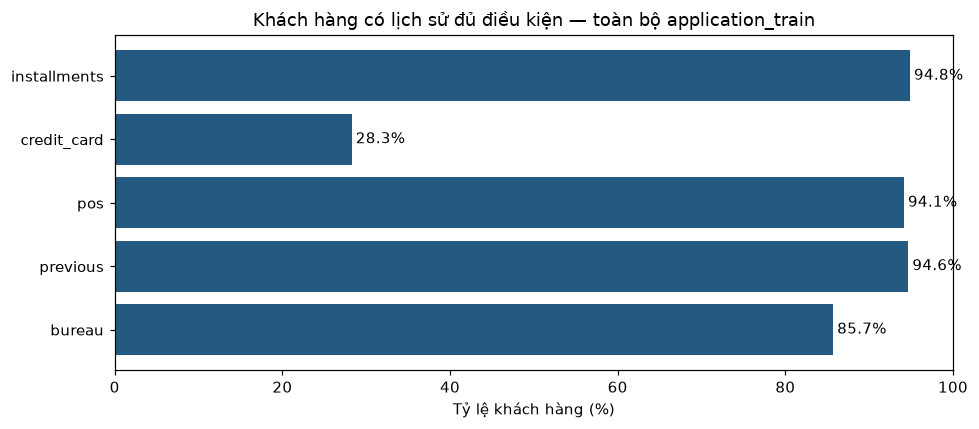

In [11]:
plot = coverage_df.loc[coverage_df.table.eq("application_train")]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(plot.group, plot.history_rate * 100, color="#245A81")
ax.set(title="Khách hàng có lịch sử đủ điều kiện — toàn bộ application_train", xlabel="Tỷ lệ khách hàng (%)", ylabel="")
ax.set_xlim(0, 100)
for i, value in enumerate(plot.history_rate):
    ax.text(value*100+0.5, i, f"{value:.1%}", va="center")
fig.tight_layout()
plt.show()

## 8. Bàn giao và giới hạn

- Bảng nhóm và bảng cuối: data/processed/features/; metadata: feature_manifest.json.
- application_train_features chứa ID, TARGET và predictors; application_test_features không có TARGET. Bỏ ID/TARGET khỏi X.
- Development/holdout tiếp tục lấy từ data/splits/train.parquet và val.parquet.
- HAS_* và count=0 chỉ biểu thị không có lịch sử đủ điều kiện; không đồng nghĩa khoản tiền bằng 0.
- Categorical và missing giữ cho preprocessing theo fold sau này. Chưa scaling, encoder học từ dữ liệu, statistical imputation hay train.
- Thiếu timestamp đầy đủ nên không bảo đảm point-in-time correctness hoàn toàn; kỳ trả khác version được thống kê riêng; bureau_balance orphan không đóng góp vào khách hàng.
- CSV báo cáo chỉ ghi reports/tables/ khi EXPORT_REPORTS=True.
REBUILD_OUTPUTS=False mặc định chỉ tái sử dụng output sau đối soát; đặt True khi chủ động muốn ghi lại các artifact dẫn xuất. Không thay đổi nguồn hoặc split.


### Trạng thái xác minh
Đã chạy tuần tự 11 code cell trên toàn bộ dữ liệu, lưu output và đối soát Parquet theo batch.
Lượt kiểm tra đặt EXPORT_REPORTS=False và REBUILD_OUTPUTS=True để ghi lại artifact dẫn xuất vừa tạo; không sửa nguồn hoặc split. Khi chạy bình thường, CSV xuất reports/tables/ và output hiện có chỉ được đối soát theo mặc định.
